In [2]:
# Importing files
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#Checking whether file exist
pathfile="Salaries.csv"
if os.path.exists(pathfile):
    print("FileFound ✅")
else:print("FileNotFoundError")


FileFound ✅


In [4]:
# loading dataset
data=pd.read_csv(pathfile)


In [5]:
# Checking shape of dataset
data.shape

(78, 6)

In [6]:
# Checking dataset information
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rank        78 non-null     str    
 1   discipline  77 non-null     str    
 2   phd         75 non-null     float64
 3   service     78 non-null     int64  
 4   sex         75 non-null     str    
 5   salary      78 non-null     int64  
dtypes: float64(1), int64(2), str(3)
memory usage: 4.7 KB


In [7]:
#  Five first rows
data.head()

,rank,discipline,phd,service,sex,salary
0,Prof,b,56.0,49,Female,186960
1,Prof,A,12.0,6,Male,93000
2,Prof,NaN,NaN,20,male,110515
3,Prof,A,NaN,31,Male,131205
4,Prof,B,20.0,18,NaN,104800


In [8]:
#  last five columns
data.tail()

,rank,discipline,phd,service,sex,salary
73,Prof,B,18.0,10,Female,105450
74,AssocProf,B,19.0,6,Female,104542
75,Prof,B,17.0,17,Female,124312
76,Prof,A,28.0,14,Female,109954
77,Prof,A,23.0,15,Female,109646


In [9]:
print(data[data["service"]<=0].count())

rank          6
discipline    6
phd           6
service       6
sex           5
salary        6
dtype: int64


In [10]:
# checking null values
data.isnull().sum()

rank          0
discipline    1
phd           3
service       0
sex           3
salary        0
dtype: int64

In [11]:
#  Checking duplicates
data.duplicated().sum()

np.int64(0)

In [12]:
# Checking impossible values
def CheckImpossible(data):
   for col in data.select_dtypes(include=["int64","float64"]).columns:
      print(col)
      a=data[col]<=0
      # print(data[col][a])
      # print(data[col][a].sum())
      condition=(data[col][a]).count()
      if condition>0:
         print(data.loc[a,col])
         print(f"Number of impossible values {condition}")
      else:print("No impossible value for ",col)
      print()

In [13]:
CheckImpossible(data)

phd
No impossible value for  phd

service
12    0
17    0
23    0
43    0
52    0
55    0
Name: service, dtype: int64
Number of impossible values 6

salary
No impossible value for  salary



In [14]:
# Check inconsistent formats
def Countfunc(data):
    for col in data.select_dtypes(include=["str"]).columns:
        print(data[col].value_counts())
        print()

In [15]:
Countfunc(data)

rank
Prof         46
AsstProf     19
AssocProf    13
Name: count, dtype: int64

discipline
B    41
A    35
b     1
Name: count, dtype: int64

sex
Female    37
Male      29
male       6
female     3
Name: count, dtype: int64



FIXING

In [17]:
# Fixing data Inconsistence
for col in data.select_dtypes(include=["str"]).columns:
   data[col]=data[col].str.title()

In [18]:
Countfunc(data)

rank
Prof         46
Asstprof     19
Assocprof    13
Name: count, dtype: int64

discipline
B    42
A    35
Name: count, dtype: int64

sex
Female    40
Male      35
Name: count, dtype: int64



In [19]:
# fixing impossible Numerical values
a=data["service"]<=0
data.loc[a,"service"]=np.nan

In [20]:
# Fixing missing values using the most frequent value under respective column
for col in data.columns:
    data[col]=data[col].fillna(data[col].mode()[0])

In [21]:
CheckImpossible(data=data)

phd
No impossible value for  phd

service
No impossible value for  service

salary
No impossible value for  salary



In [22]:
#  Fixing data typr incorrectness
data["phd"]=data["phd"].astype("int",errors="ignore")

In [23]:
# After data cleaning

In [24]:
#  Shape
data.shape

(78, 6)

In [25]:
# Check datatypes
data.dtypes

rank              str
discipline        str
phd             int64
service       float64
sex               str
salary          int64
dtype: object

In [26]:
#  First five rows
data.head()

,rank,discipline,phd,service,sex,salary
0,Prof,B,56,49.0,Female,186960
1,Prof,A,12,6.0,Male,93000
2,Prof,B,4,20.0,Male,110515
3,Prof,A,4,31.0,Male,131205
4,Prof,B,20,18.0,Female,104800


In [27]:
# Last five rows
data.tail()

,rank,discipline,phd,service,sex,salary
73,Prof,B,18,10.0,Female,105450
74,Assocprof,B,19,6.0,Female,104542
75,Prof,B,17,17.0,Female,124312
76,Prof,A,28,14.0,Female,109954
77,Prof,A,23,15.0,Female,109646


In [ ]:
#  Descriptive Statistics 
data.describe().style.set_properties(**{"background-color":"cyan","color":"blue","border":"green 2px solid"})

,phd,service,salary,PhdProdService
count,78.000000,78.000000,78.000000,78.000000
mean,18.551282,15.282051,108023.782051,1.012911
std,12.415582,11.873683,28293.661022,1.291015
min,1.000000,1.000000,57800.000000,0.176471
25%,8.250000,5.250000,88612.500000,0.534722
50%,18.000000,14.500000,104671.000000,0.788889
75%,25.750000,20.750000,126774.750000,0.988889
max,56.000000,51.000000,186960.000000,8.250000


In [50]:
# Categorical descriptive statistics
data.describe(include="str").style.set_properties(**{"background-color":"cyan","color":"blue","border":"green 2px solid"})

,rank,discipline,sex
count,78,78,78
unique,3,2,2
top,Prof,B,Female
freq,46,43,43


In [29]:
data["rank"].value_counts()

rank
Prof         46
Asstprof     19
Assocprof    13
Name: count, dtype: int64

CHARTS

Text(0, 0.5, 'Salary')

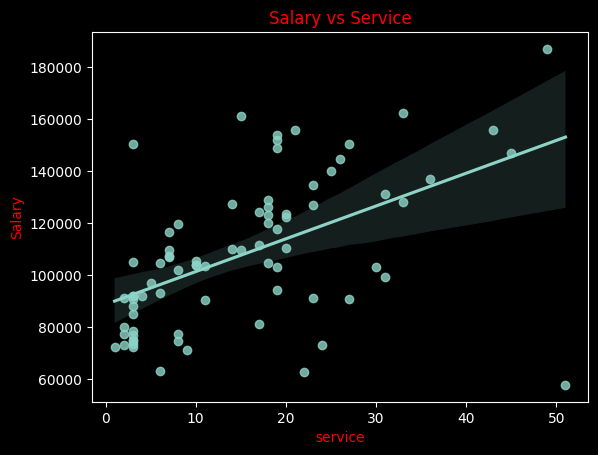

In [30]:
# Regline plot
sns.regplot(
    data=data,
    x="service",
    y="salary",
    scatter=True,
    fit_reg=True
)
plt.title("Salary vs Service",color="red")
plt.xlabel('service',color="red")
plt.ylabel("Salary",color="red")

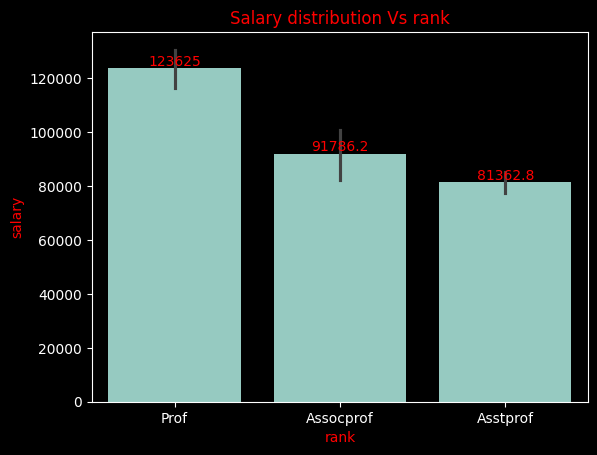

In [31]:
ax=sns.barplot(
    data,
    x="rank",
    y="salary"
)
for label in ax.containers:
    ax.bar_label(label,color="red")
plt.title("Salary distribution Vs rank",color="red")
plt.xlabel("rank",color="red")
plt.ylabel("salary",color="red")
plt.show()

MODEL

In [32]:
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

In [33]:
# Feature Engineering
data["PhdProdService"]=data.eval("service/phd")
data.shape

(78, 7)

In [34]:
#feature-target separation
feature=data.drop(columns=["salary"])
target=data["salary"]

In [35]:
# splitting test and train set
x_train,x_test,y_train,y_test=train_test_split(
    feature,
    target,
    test_size=0.2,
    random_state=42
)

In [36]:
x_train.shape

(62, 6)

In [37]:
x_test.shape

(16, 6)

In [38]:
y_train.shape

(62,)

In [39]:
y_test.shape

(16,)

In [40]:
# encoding using labelencoder
for col in x_train.select_dtypes(include=["str"]).columns:
     encoder=LabelEncoder()
     x_train[col]=encoder.fit_transform(x_train[col])
     x_test[col]=encoder.transform(x_test[col])
     


In [41]:
#scaling
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [42]:
# algorithm selection
model=LinearRegression()

In [43]:
# model training
model.fit(x_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [44]:
y_train_predict=model.predict(x_train_scaled)
r2score=r2_score(y_train,y_train_predict)
print(f"Training R2 score {r2score:.4f}")
MSE=mean_squared_error(y_train,y_train_predict)
print(f"Mean squared error in training {MSE:.4f}")
print("std: ",data["salary"].std())

Training R2 score 0.5448
Mean squared error in training 322622548.2075
std:  28293.66102226417


In [45]:
y_predict=model.predict(x_test_scaled)

In [46]:
print(r2_score(y_test,y_predict))

0.6552991042269392
